# 1.0 — EDA & data cleaning: shelf gaps (Roboflow) + fully stocked shelves (SKU-110K)

**Project goal:** detect **empty shelf space**, the places where products need to be restocked.

This notebook covers the Week 1 data work:

| # | Step | Output |
|---|------|--------|
| 1 | Load and explore the Roboflow *retail shelf availability* dataset (our gap labels) | — |
| 2 | Fix the labels: merge class `"0"` into `gap`, drop the empty `UROP` category | single class `gap` |
| 3 | Look at image and box statistics, sanity-check the boxes | — |
| 4 | Find near-duplicate photos (Roboflow flip copies + re-uploads) and measure leakage in the original split | duplicate groups |
| 5 | Re-split ~70/15/15 **by duplicate group**, so each original photo lands in only one split; keep the original split for the leakage comparison | `data/interim/retail-gap/manifest.csv` |
| 6 | Explore SKU-110K and keep **only fully stocked shelves** as "no gap" background images | `data/interim/retail-gap/sku110k_negatives.csv` |
| 7 | Write YOLO-format datasets | `data/processed/retail-gap/`, `data/processed/retail-gap-original-split/` |

**Why we don't use all of SKU-110K:** its boxes mark *products*, not gaps. Any SKU-110K image that shows empty shelf
space would teach the model that empty space is background, the opposite of what we want. We only use it as a
source of shelves with **no gaps at all**, added with empty label files.

**Inputs** (`data/raw/`, gitignored):
- `retail-shelf-availability-coco/`: Roboflow COCO export, v2 ([Roboflow Universe](https://universe.roboflow.com/srm-university-52jqz/retail-shelf-availability/dataset/2))
- `SKU-110K/`: images + YOLO labels downloaded from the Ultralytics Platform NDJSON export (`sku110k.ndjson`)

**Environment:** the project venv (`requirements.txt` + `imagehash`). Run top to bottom; every step is deterministic (`SEED = 42`).

In [1]:
import json
import shutil
from collections import Counter

import imagehash
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

from barcode.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR

RF_DIR = RAW_DATA_DIR / "retail-shelf-availability-coco"
SKU_DIR = RAW_DATA_DIR / "SKU-110K"
FIG_DIR = FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
SPLITS = ["train", "val", "test"]
RF_FOLDER = {"train": "train", "val": "valid", "test": "test"}  # YOLO split name -> Roboflow folder

%config InlineBackend.figure_formats = ["jpeg"]  # photo grids as PNG make the notebook huge
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/Users/qpali/barcode-project/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-14 18:46:32.602 -08:00 | INFO     | barcode.config:<module>:11 - PROJ_ROOT path is: /Users/qpali/barcode-project


## 1. Roboflow dataset: load

From the export's `README.roboflow.txt`:
- **Pre-processing:** auto-orient, then **resize to 416×416 (stretch)**. The original aspect ratio is lost.
- **Augmentation:** *3 versions of each source image*, with a 50% chance of a horizontal flip.

Roboflow names every copy `<source>_jpg.rf.<hash>.jpg`, so the part before `.rf.` (the **stem**) identifies the source photo.

In [2]:
img_rows, box_rows = [], []
for split in SPLITS:
    coco = json.loads((RF_DIR / RF_FOLDER[split] / "_annotations.coco.json").read_text())
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    for im in coco["images"]:
        img_rows.append({"orig_split": split, "image_id": im["id"], "file": im["file_name"],
                         "width": im["width"], "height": im["height"]})
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        box_rows.append({"orig_split": split, "image_id": a["image_id"],
                         "category": cats[a["category_id"]], "x": x, "y": y, "w": w, "h": h})

imgs = pd.DataFrame(img_rows)
imgs["path"] = [RF_DIR / RF_FOLDER[s] / f for s, f in zip(imgs["orig_split"], imgs["file"])]
imgs["stem"] = imgs["file"].str.replace(r"_jpg\.rf\..*$", "", regex=True)
# DSC* are real store photos; 235_* and *lowResFull* are one lab shelf photographed many times (see §3)
imgs["scene"] = np.where(imgs["file"].str.startswith("DSC"), "store", "lab")
imgs["uid"] = imgs["orig_split"] + "/" + imgs["file"]

boxes = pd.DataFrame(box_rows).merge(imgs[["orig_split", "image_id", "uid", "scene"]],
                                     on=["orig_split", "image_id"])
print("categories:", cats)
print(f"{len(imgs)} images, {len(boxes)} boxes")
imgs.head(3)

categories: {0: 'UROP', 1: '0', 2: 'gap'}
4588 images, 23015 boxes


,orig_split,image_id,file,width,height,path,stem,scene,uid
0,train,0,DSC04789_jpg.rf.b3aed0b1787f34edd5683ba88cff3b...,416,416,/Users/qpali/barcode-project/data/raw/retail-s...,DSC04789,store,train/DSC04789_jpg.rf.b3aed0b1787f34edd5683ba8...
1,train,1,DSC05127_jpg.rf.b2be25ef317fa1a52cd2a76ac5e8fb...,416,416,/Users/qpali/barcode-project/data/raw/retail-s...,DSC05127,store,train/DSC05127_jpg.rf.b2be25ef317fa1a52cd2a76a...
2,train,2,DSC05093_jpg.rf.b3f28e5727c97dc658921dacc74b64...,416,416,/Users/qpali/barcode-project/data/raw/retail-s...,DSC05093,store,train/DSC05093_jpg.rf.b3f28e5727c97dc658921dac...


In [3]:
overview = pd.DataFrame({
    "images": imgs.groupby("orig_split").size(),
    "boxes": boxes.groupby("orig_split").size(),
    "unique stems": imgs.groupby("orig_split")["stem"].nunique(),
}).reindex(SPLITS)
overview.loc["total"] = [len(imgs), len(boxes), imgs["stem"].nunique()]
overview["images per stem"] = (overview["images"] / overview["unique stems"]).round(2)
overview["boxes per image"] = (overview["boxes"] / overview["images"]).round(2)
overview

,images,boxes,unique stems,images per stem,boxes per image
orig_split,,,,,
train,3682,18114,1028,3.58,4.92
val,604,3131,501,1.21,5.18
test,302,1770,273,1.11,5.86
total,4588,23015,1093,4.20,5.02


In [4]:
copies = imgs.groupby(["orig_split", "stem"]).size().rename("copies").reset_index()
pd.crosstab(copies["copies"], copies["orig_split"]).reindex(columns=SPLITS).rename_axis(
    "files per stem", axis=0)

orig_split,train,val,test
files per stem,,,
1,79,403,246
2,232,93,25
3,153,5,2
4,291,0,0
5,134,0,0
6,133,0,0
7,4,0,0
9,1,0,0
11,1,0,0


**Observations**
- Training has several files per stem (often 3–6, up to 11), as the README describes. Some stems also appear more
  than once in **val/test**.
- Stems whose total count across splits is higher than the per-split count mean **the same source photo is in more than
  one split**. That is leakage; §5 measures it.

## 2. Class labels: `UROP`, `"0"`, `gap`

In [5]:
cat_counts = pd.crosstab(boxes["category"], boxes["orig_split"]).reindex(
    index=list(cats.values()), columns=SPLITS, fill_value=0)
cat_counts["total"] = cat_counts.sum(axis=1)
cat_counts["images"] = boxes.groupby("category")["uid"].nunique().reindex(cat_counts.index, fill_value=0)
cat_counts

orig_split,train,val,test,total,images
category,,,,,
UROP,0,0,0,0,0
0,719,134,43,896,137
gap,17395,2997,1727,22119,4451


In [6]:
classes_per_image = boxes.groupby("uid")["category"].agg(lambda s: " + ".join(sorted(set(s))))
print("class combinations per image:")
print(classes_per_image.value_counts().to_string())
print("\nimages with no boxes at all:", len(set(imgs["uid"]) - set(boxes["uid"])))
print("scene of images using class '0':",
      imgs.set_index("uid").loc[classes_per_image[classes_per_image == "0"].index, "scene"].value_counts().to_dict())

class combinations per image:
category
gap    4451
0       137

images with no boxes at all: 0
scene of images using class '0': {'store': 137}


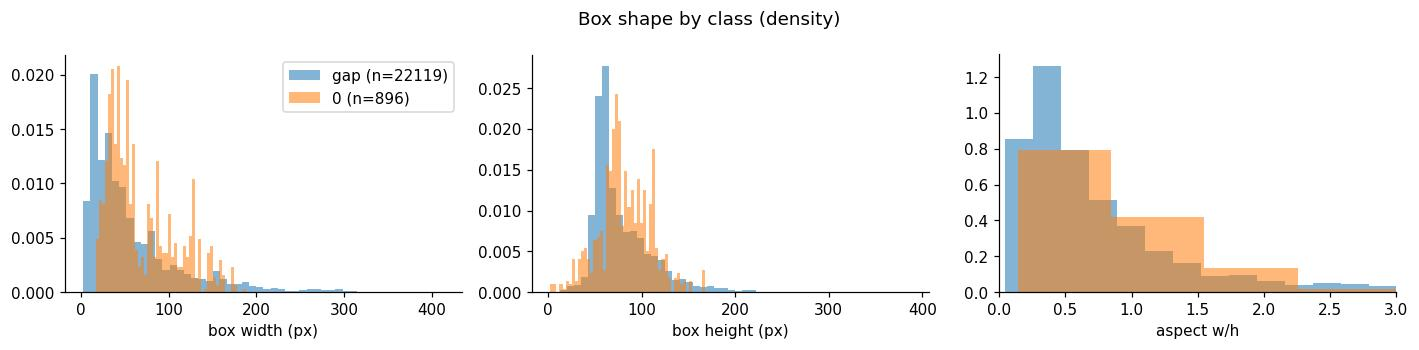

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for cat, color in [("gap", "tab:blue"), ("0", "tab:orange")]:
    b = boxes[boxes["category"] == cat]
    for ax, col, label in zip(axes, ["w", "h", None], ["box width (px)", "box height (px)", "aspect w/h"]):
        vals = b[col] if col else b["w"] / b["h"]
        ax.hist(vals, bins=50, density=True, alpha=0.55, color=color, label=f"{cat} (n={len(b)})")
        ax.set_xlabel(label)
axes[0].legend()
axes[2].set_xlim(0, 3)
fig.suptitle("Box shape by class (density)")
plt.tight_layout()
plt.show()

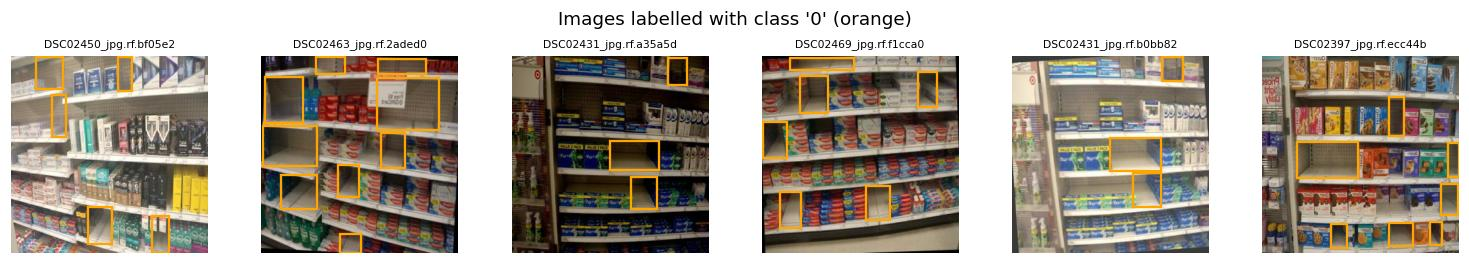

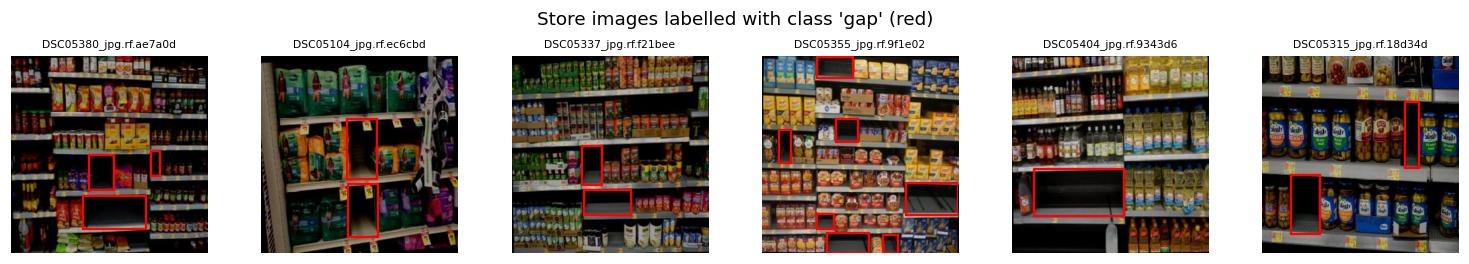

In [8]:
def draw(ax, row, img_boxes, colors=None, title=None):
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    for b in img_boxes.itertuples():
        color = (colors or {}).get(b.category, "red")
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, lw=1.5, ec=color))
    ax.set_title(title or row["file"][:22], fontsize=7)
    ax.axis("off")


def example_grid(uids, n_cols=6, colors=None, title=None, fname=None):
    by_uid = imgs.set_index("uid")
    n_rows = int(np.ceil(len(uids) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.4 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, uid in zip(axes.flat, uids):
        draw(ax, by_uid.loc[uid], boxes[boxes["uid"] == uid], colors)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


rng = np.random.default_rng(SEED)
uids_0 = rng.choice(classes_per_image[classes_per_image == "0"].index, 6, replace=False)
uids_gap = rng.choice(classes_per_image[(classes_per_image == "gap")
                                        & classes_per_image.index.isin(imgs.loc[imgs.scene == "store", "uid"])].index,
                      6, replace=False)
colors = {"0": "orange", "gap": "red"}
example_grid(list(uids_0), colors=colors, title="Images labelled with class '0' (orange)", fname="class0_examples.jpg")
example_grid(list(uids_gap), colors=colors, title="Store images labelled with class 'gap' (red)", fname="gap_examples.jpg")

**Decision: merge `"0"` into `gap`, drop `UROP`.**
- `UROP` has **0 boxes**. It is the project name Roboflow keeps as a parent category (`supercategory` of the other two), not a real class.
- `"0"` is used on a small set of store photos and **never in the same image as `gap`**. The examples show the same
  thing as `gap`: empty shelf space. It is a labelling batch that got a different class name, not a different concept. Its
  boxes are a bit larger on average, which fits that.
- After cleaning there is **one class: `0: gap`**.

## 3. Images: size, scene type, brightness

One pass over all images computes brightness plus a **perceptual hash** of each image *and of its mirror image*.
We use the hashes in §5 to find flipped copies.

In [9]:
print("image sizes:", Counter(zip(imgs["width"], imgs["height"])))

stats = []
for p in tqdm(imgs["path"], desc="hashing"):
    im = Image.open(p).convert("L")
    stats.append((np.asarray(im).mean(), imagehash.phash(im), imagehash.phash(ImageOps.mirror(im))))
imgs["brightness"] = [s[0] for s in stats]
imgs["phash"] = [s[1] for s in stats]
imgs["phash_flip"] = [s[2] for s in stats]

pd.crosstab(imgs["scene"], imgs["orig_split"], margins=True).reindex(columns=SPLITS + ["All"])

image sizes: Counter({(416, 416): 4588})


hashing:   0%|          | 0/4588 [00:00<?, ?it/s]

hashing:   0%|          | 1/4588 [00:00<08:27,  9.04it/s]

hashing:   3%|▎         | 120/4588 [00:00<00:06, 673.20it/s]

hashing:   5%|▌         | 241/4588 [00:00<00:04, 912.33it/s]

hashing:   8%|▊         | 348/4588 [00:00<00:04, 973.47it/s]

... (33 outputs left out)

hashing:  96%|█████████▋| 4422/4588 [00:03<00:00, 1214.05it/s]

hashing:  99%|█████████▉| 4544/4588 [00:03<00:00, 1214.86it/s]

hashing: 100%|██████████| 4588/4588 [00:03<00:00, 1149.12it/s]

orig_split,train,val,test,All
scene,,,,
lab,433,84,56,573
store,3249,520,246,4015
All,3682,604,302,4588


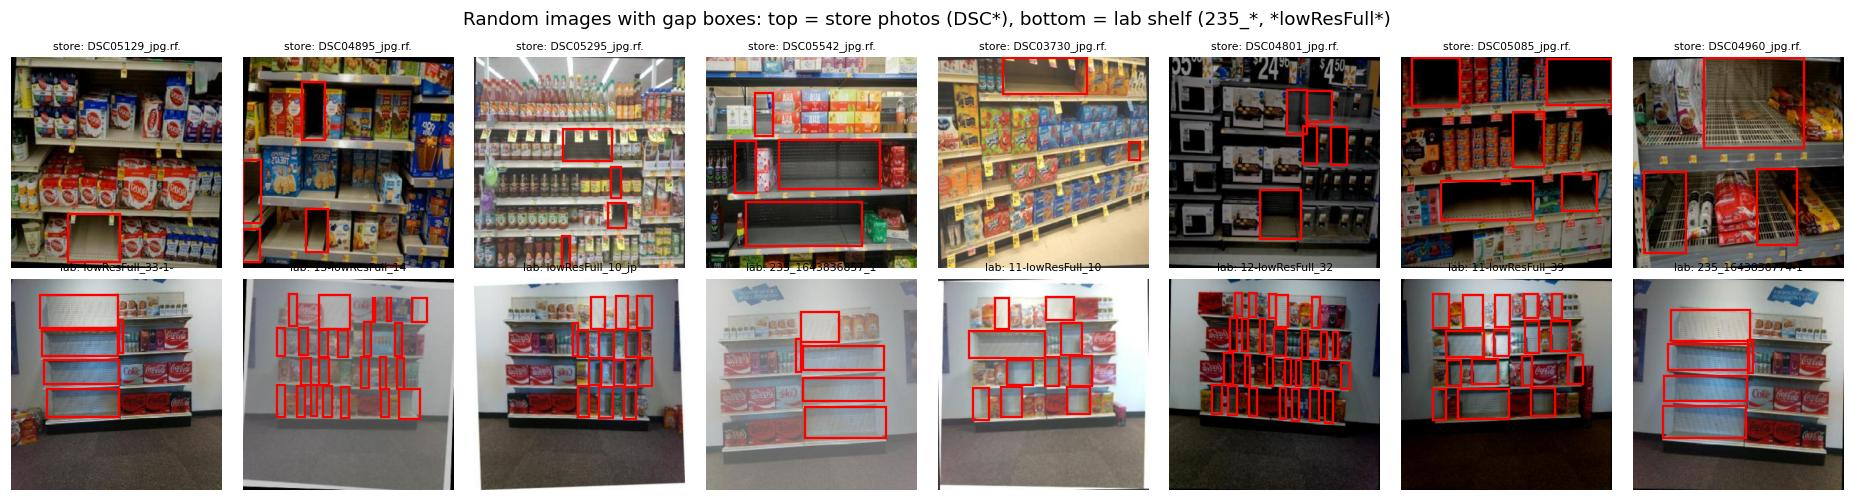

In [10]:
fig, axes = plt.subplots(2, 8, figsize=(17, 4.6))
for row_axes, scene in zip(axes, ["store", "lab"]):
    sample = imgs[imgs["scene"] == scene].sample(8, random_state=SEED)
    for ax, (_, r) in zip(row_axes, sample.iterrows()):
        draw(ax, r, boxes[boxes["uid"] == r["uid"]], title=f"{scene}: {r['file'][:16]}")
fig.suptitle("Random images with gap boxes: top = store photos (DSC*), bottom = lab shelf (235_*, *lowResFull*)")
plt.tight_layout()
fig.savefig(FIG_DIR / "scene_examples.jpg", bbox_inches="tight")
plt.show()

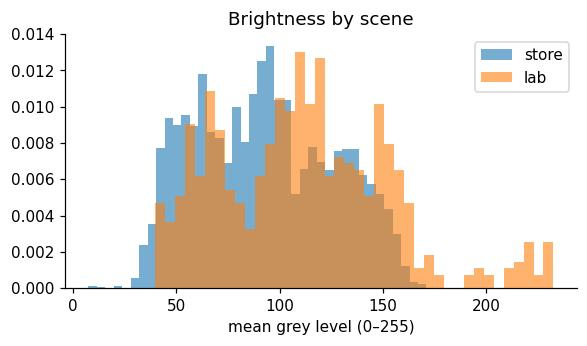

,count,mean,std,min,25%,50%,75%,max
scene,,,,,,,,
lab,573.0,111.6,41.5,39.8,77.6,109.7,138.1,232.5
store,4015.0,92.4,33.1,7.5,63.9,91.3,118.8,171.0


In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
for scene in ["store", "lab"]:
    ax.hist(imgs.loc[imgs.scene == scene, "brightness"], bins=40, alpha=0.6, label=scene, density=True)
ax.set_xlabel("mean grey level (0–255)")
ax.legend()
ax.set_title("Brightness by scene")
plt.show()
imgs.groupby("scene")["brightness"].describe().round(1)

**Observations**
- Every image is **416×416**, stretched from the original aspect ratio. Products and gaps are distorted, more so on
  portrait photos. The planned Roboflow re-export (640 px, original aspect, no augmentation) would fix this.
- About **88% are real store photos** (`DSC*`, many different stores and aisles). About **12% show one lab shelf** that was
  photographed over and over with products rearranged (`235_*`, `*lowResFull*`). Lab images look very similar to
  each other, so they are almost impossible to separate by "near-duplicate" rules alone. We stratify the split by scene
  so every split gets its share of both.

## 4. Box statistics and sanity checks

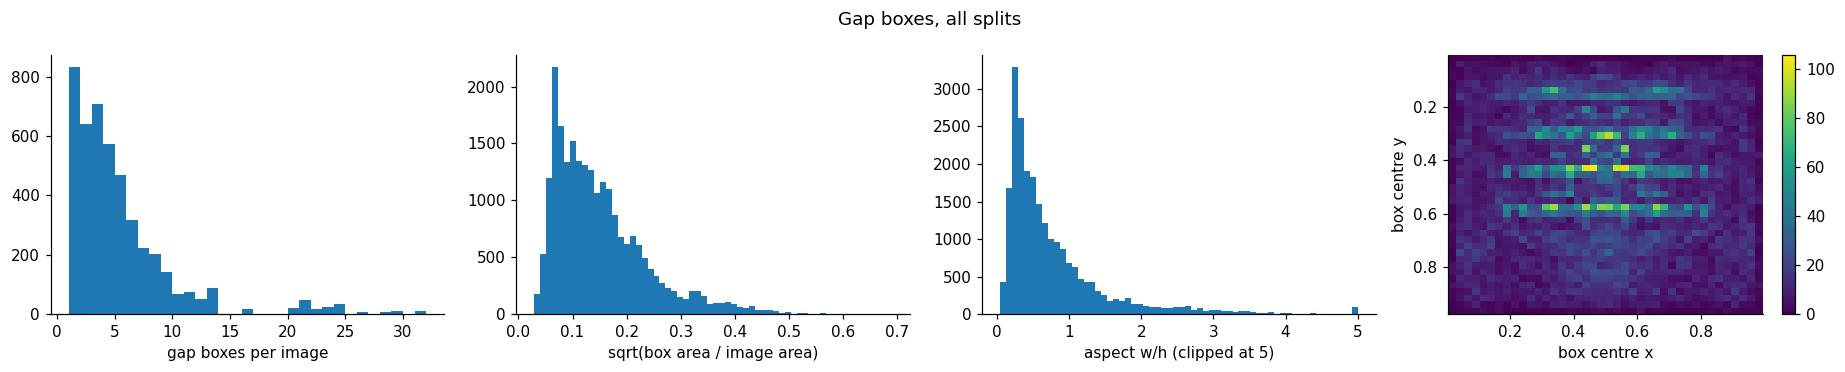

count    4588.00
mean        5.02
std         4.80
min         1.00
25%         2.00
50%         4.00
75%         6.00
max        31.00


In [12]:
W = H = 416
boxes["cx"] = (boxes["x"] + boxes["w"] / 2) / W
boxes["cy"] = (boxes["y"] + boxes["h"] / 2) / H
boxes["rel_area"] = boxes["w"] * boxes["h"] / (W * H)
per_image = boxes.groupby("uid").size()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
axes[0].hist(per_image, bins=range(1, per_image.max() + 2), color="tab:blue")
axes[0].set_xlabel("gap boxes per image")
axes[1].hist(np.sqrt(boxes["rel_area"]), bins=60, color="tab:blue")
axes[1].set_xlabel("sqrt(box area / image area)")
axes[2].hist(np.clip(boxes["w"] / boxes["h"], 0, 5), bins=60, color="tab:blue")
axes[2].set_xlabel("aspect w/h (clipped at 5)")
hb = axes[3].hist2d(boxes["cx"], boxes["cy"], bins=40, cmap="viridis")
axes[3].invert_yaxis()
axes[3].set_xlabel("box centre x")
axes[3].set_ylabel("box centre y")
fig.colorbar(hb[3], ax=axes[3])
fig.suptitle("Gap boxes, all splits")
plt.tight_layout()
fig.savefig(FIG_DIR / "box_stats.png", bbox_inches="tight")
plt.show()

print(per_image.describe().round(2).to_string())

In [13]:
def iou_matrix(b):
    x1, y1, x2, y2 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(x2[:, None], x2) - np.maximum(x1[:, None], x1), 0, None)
    ih = np.clip(np.minimum(y2[:, None], y2) - np.maximum(y1[:, None], y1), 0, None)
    inter = iw * ih
    area = b[:, 2] * b[:, 3]
    return inter / (area[:, None] + area - inter)


dup_pairs = 0
for _, g in boxes.groupby("uid"):
    if len(g) > 1:
        m = iou_matrix(g[["x", "y", "w", "h"]].to_numpy(float))
        dup_pairs += int((np.triu(m, 1) > 0.9).sum())

checks = {
    "degenerate (w or h < 1 px)": int(((boxes.w < 1) | (boxes.h < 1)).sum()),
    "outside the image": int(((boxes.x < 0) | (boxes.y < 0) | (boxes.x + boxes.w > W + 0.5)
                              | (boxes.y + boxes.h > H + 0.5)).sum()),
    "tiny (w or h < 8 px)": int(((boxes.w < 8) | (boxes.h < 8)).sum()),
    "huge (> 50% of image)": int((boxes.rel_area > 0.5).sum()),
    "near-duplicate box pairs (IoU > 0.9)": dup_pairs,
}
pd.Series(checks, name="count").to_frame()

,count
degenerate (w or h < 1 px),0
outside the image,0
tiny (w or h < 8 px),470
huge (> 50% of image),0
near-duplicate box pairs (IoU > 0.9),0


**Observations**
- Most images have only a few gap boxes, with a long tail of images that are mostly empty.
- Boxes are mid-sized, usually taller than wide, and spread over the whole frame. There is no strong position bias.
- The boxes are clean: none are degenerate, outside the image, or stacked duplicates. About 2% are smaller than 8 px on a
  side at 416 px. That is small but plausible for distant gaps, so they are kept.
- **Every image has at least one gap.** The model never sees a "no gap" shelf, which is why §6 adds fully stocked SKU-110K shelves.

## 5. Near-duplicates and leakage

A copy can show up in two ways:
1. **Same Roboflow stem**: an augmentation copy of the same upload.
2. **Same picture, different stem**: the same photo uploaded twice (e.g. `lowResFull_103` and `lowResFull_103-1-`), possibly mirrored.

For (2) we compare 64-bit perceptual hashes. The distance between two images is the **smaller** of
`hash(a) vs hash(b)` and `hash(a) vs hash(mirror(b))`, so horizontally flipped copies count as the same picture.

pairs with different stems, by scene and distance:


dist,0,2,4,6,8,10,12,14,16
scene,,,,,,,,,
lab,32,118,332,990,2036,3806,6000,8550,11292
mixed,0,0,0,0,0,0,9,83,599
store,0,10,28,124,198,264,310,876,3619


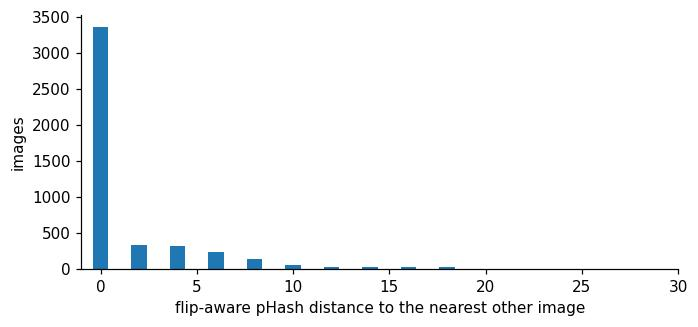

73% of images have an exact (distance 0) copy somewhere in the dataset


In [14]:
LUT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def pack(hashes):
    return np.array([int(str(h), 16) for h in hashes], dtype=np.uint64)


def hamming_row(a, others):
    return LUT[(a ^ others).view(np.uint8).reshape(-1, 8)].sum(axis=1)


P, PF = pack(imgs["phash"]), pack(imgs["phash_flip"])
n = len(imgs)
stems = imgs["stem"].to_numpy()
scenes = imgs["scene"].to_numpy()
pairs = []  # (i, j, distance) for every pair with distance <= 16
nn_dist = np.full(n, 64)
for i in range(n):
    d = np.minimum(hamming_row(P[i], P), hamming_row(P[i], PF))
    d[i] = 64
    nn_dist[i] = d.min()
    j = np.nonzero(d[i + 1:] <= 16)[0] + i + 1
    pairs += [(i, int(k), int(d[k])) for k in j]
pairs = pd.DataFrame(pairs, columns=["i", "j", "dist"])
pairs["same_stem"] = stems[pairs["i"]] == stems[pairs["j"]]
pairs["scene"] = np.where(scenes[pairs["i"]] == scenes[pairs["j"]], scenes[pairs["i"]], "mixed")
print("pairs with different stems, by scene and distance:")
display(pd.crosstab(pairs.loc[~pairs.same_stem, "scene"], pairs.loc[~pairs.same_stem, "dist"]))

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(*np.unique(nn_dist, return_counts=True))
ax.set_xlabel("flip-aware pHash distance to the nearest other image")
ax.set_ylabel("images")
ax.set_xlim(-1, 30)
plt.show()
print(f"{(nn_dist == 0).mean():.0%} of images have an exact (distance 0) copy somewhere in the dataset")

In [15]:
def union_find_groups(store_max, lab_max):
    # group images that share a stem, or are within their scene's pHash distance of each other
    parent = np.arange(n)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    first = {}
    for i, s in enumerate(stems):  # same stem -> same group
        if s in first:
            parent[find(i)] = find(first[s])
        else:
            first[s] = i
    close = ((pairs["scene"] == "store") & (pairs["dist"] <= store_max)) | (
        (pairs["scene"] == "lab") & (pairs["dist"] <= lab_max))
    for i, j in pairs.loc[close, ["i", "j"]].to_numpy():
        parent[find(i)] = find(j)
    return np.array([find(i) for i in range(n)])


def group_table(scene, thresholds, other):
    rows = []
    for t in thresholds:
        g = union_find_groups(t, other) if scene == "store" else union_find_groups(other, t)
        sizes = pd.Series(g[scenes == scene]).value_counts()
        rows.append({f"{scene} pHash <=": t, "groups": len(sizes), "largest": sizes.iloc[0],
                     "top-5 sizes": list(sizes.iloc[:5])})
    return pd.DataFrame(rows)


print("store photos (lab fixed at 4), then lab shelf (store fixed at 12); stem copies are always grouped")
display(group_table("store", [-1, 4, 8, 10, 12, 14, 16], other=4))
display(group_table("lab", [-1, 0, 2, 4, 6, 8], other=12))

store photos (lab fixed at 4), then lab shelf (store fixed at 12); stem copies are always grouped


,store pHash <=,groups,largest,top-5 sizes
0,-1,973,6,"[6, 6, 6, 6, 6]"
1,4,958,14,"[14, 11, 11, 11, 10]"
2,8,932,21,"[21, 14, 14, 14, 11]"
3,10,916,21,"[21, 19, 16, 14, 14]"
4,12,885,21,"[21, 19, 18, 18, 16]"
5,14,701,72,"[72, 61, 48, 43, 41]"
6,16,118,3603,"[3603, 11, 10, 8, 8]"


,lab pHash <=,groups,largest,top-5 sizes
0,-1,120,11,"[11, 10, 9, 9, 9]"
1,0,109,19,"[19, 17, 16, 13, 11]"
2,2,85,29,"[29, 26, 24, 22, 17]"
3,4,50,70,"[70, 68, 37, 33, 28]"
4,6,14,236,"[236, 194, 42, 18, 18]"
5,8,8,314,"[314, 194, 18, 15, 13]"


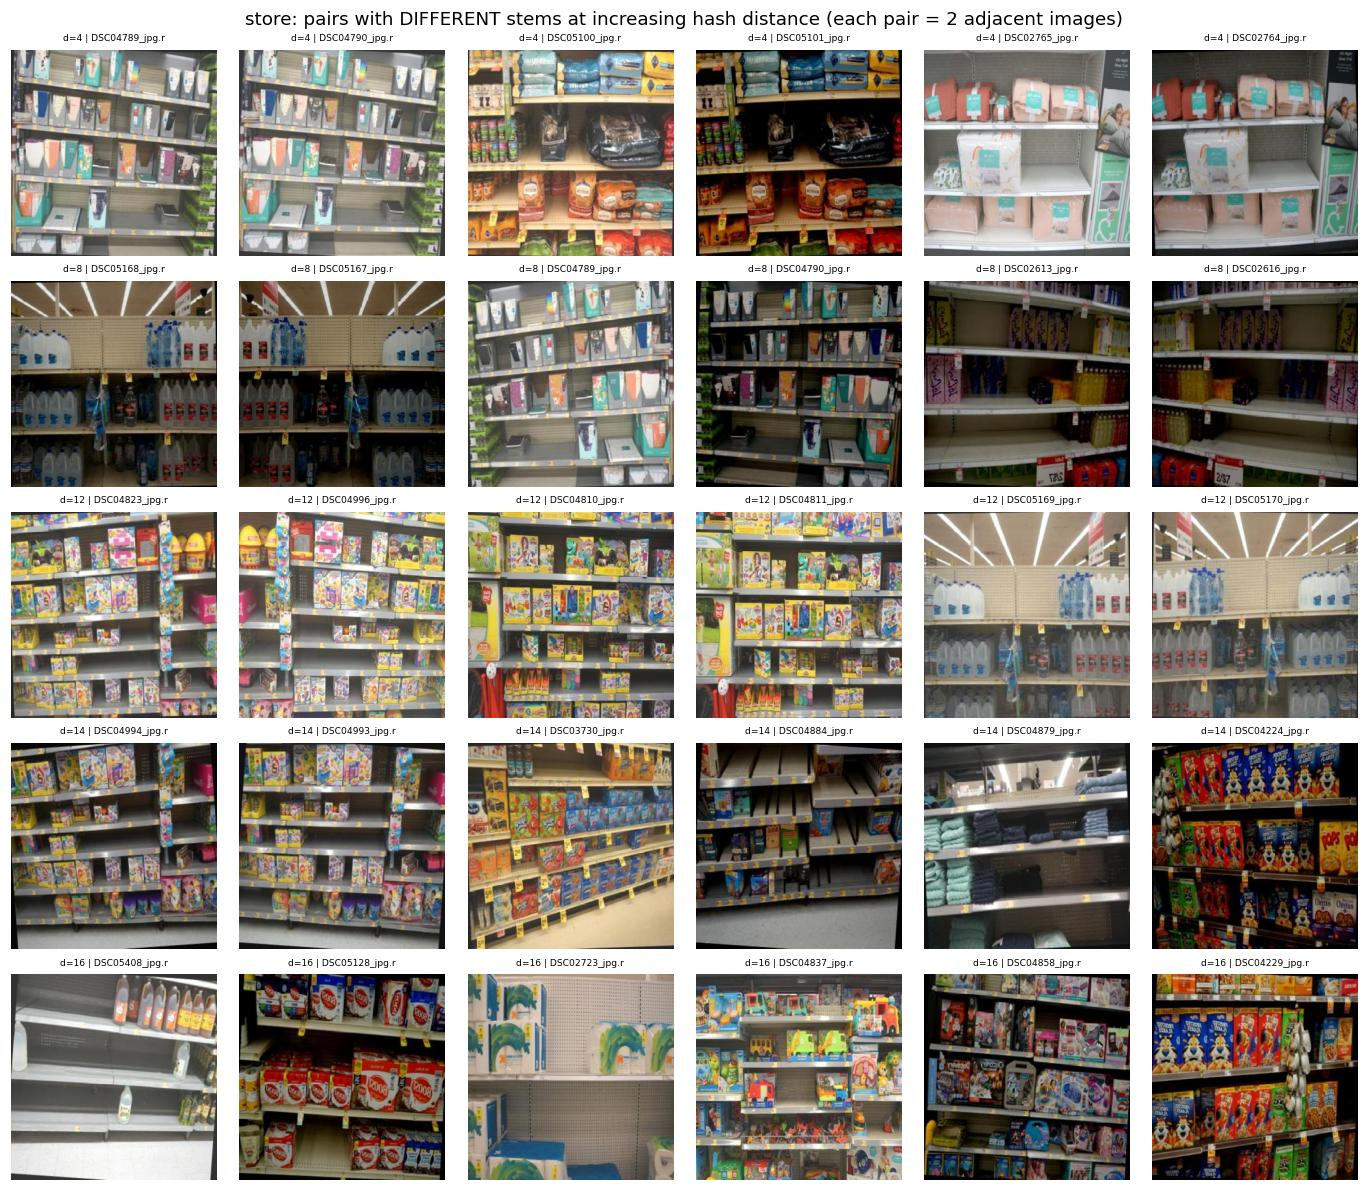

In [16]:
def show_pairs(scene, dists, per_dist=3, fname=None):
    by = pairs[~pairs["same_stem"] & (pairs["scene"] == scene)]
    fig, axes = plt.subplots(len(dists), 2 * per_dist, figsize=(2.1 * 2 * per_dist, 2.2 * len(dists)))
    for row_axes, d in zip(axes, dists):
        sel = by[by["dist"] == d].sample(per_dist, random_state=SEED)
        for k, (i, j) in enumerate(sel[["i", "j"]].to_numpy()):
            for ax, idx in zip(row_axes[2 * k: 2 * k + 2], (i, j)):
                ax.imshow(Image.open(imgs.loc[idx, "path"]).convert("RGB"))
                ax.set_title(f"d={d} | {imgs.loc[idx, 'file'][:14]}", fontsize=6)
                ax.axis("off")
    fig.suptitle(f"{scene}: pairs with DIFFERENT stems at increasing hash distance (each pair = 2 adjacent images)")
    plt.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


show_pairs("store", [4, 8, 12, 14, 16], fname="near_duplicate_pairs_store.jpg")

**Store photos.** Up to distance **12**, store pairs with different stems are the same picture: mirrored,
re-uploaded, or consecutive shots of the same shelf seconds apart. At 14 it is mixed, and at 16 they are different
shelves that union-find chains into one giant group. Store near-duplicates are sparse, so ≤ 12 does not chain.

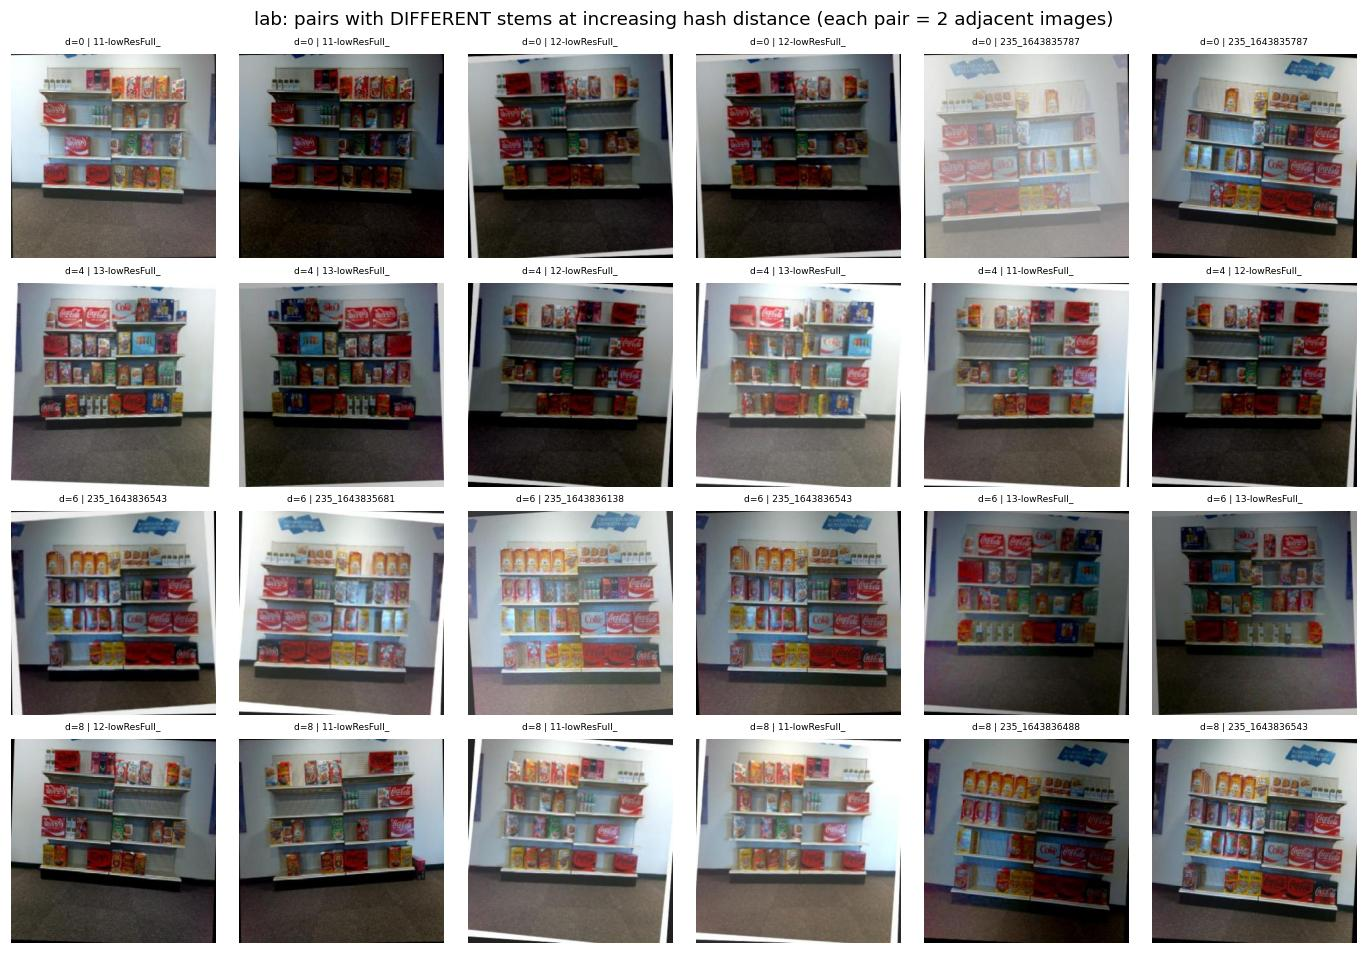

In [17]:
show_pairs("lab", [0, 4, 6, 8], fname="near_duplicate_pairs_lab.jpg")

**Lab shelf.** All lab photos show the *same* shelf from nearly the same spot, so their hashes are close by nature.
From distance **6** union-find merges the lab set into two giant groups (~240 and ~190 of 573 images), which can no
longer be split. Some lab pairs at 6–8 are still the same arrangement, so **lab overlap between splits cannot be removed
entirely**. It is one scene. For that reason we also report a **store-only** mAP as the headline number (see §9).

> **Rule:** two images are in the same group if they share a Roboflow stem, or their flip-aware pHash distance is
> **≤ 12 (store)** / **≤ 4 (lab)**.

For **evaluation** we go one step further and keep a single image per *copy cluster* (same stem or distance 0).
That way flipped copies of one photo are never counted twice in val/test, as the plan asks.

In [18]:
STORE_THRESHOLD, LAB_THRESHOLD = 12, 4
imgs["group"] = union_find_groups(STORE_THRESHOLD, LAB_THRESHOLD)
imgs["copy_cluster"] = union_find_groups(0, 0)
# a group's scene is its majority scene (groups are never mixed in practice)
imgs["group_scene"] = imgs.groupby("group")["scene"].transform(lambda s: s.mode()[0])
print(f"{imgs['group'].nunique()} groups, {imgs['copy_cluster'].nunique()} copy clusters, "
      f"mixed-scene groups: {int((imgs.groupby('group')['scene'].nunique() > 1).sum())}")

# Leakage in the ORIGINAL split: val/test images whose group also has images in train
train_groups = set(imgs.loc[imgs.orig_split == "train", "group"])
train_stems = set(imgs.loc[imgs.orig_split == "train", "stem"])
leak = {}
for split in ["val", "test"]:
    sub = imgs[imgs["orig_split"] == split]
    leak[split] = {"images": len(sub),
                   "same stem in train": f"{sub['stem'].isin(train_stems).mean():.0%}",
                   "same group in train": f"{sub['group'].isin(train_groups).mean():.0%}"}
pd.DataFrame(leak)

935 groups, 1082 copy clusters, mixed-scene groups: 0


,val,test
images,604,302
same stem in train,88%,88%
same group in train,89%,90%


**This is the main problem with the original split.** Most val and test images have a copy, often just a mirrored
one, sitting in train. Any mAP measured on the original split mostly measures memorisation. We keep the original
split anyway (§7), so we can show this gap later with numbers: same model, original split vs. grouped split.

## 6. Cleaning and the grouped re-split

**Label fix:** every box becomes class `0 = gap`.

**Split:** groups are shuffled (`SEED`) and assigned greedily to train/val/test so that each split reaches ~70/15/15
of the **unique photos** (copy clusters). This is done separately for store and lab groups, so every split has both scenes.
A whole group always goes to one split.

**Copies:** train keeps every file, since copies are harmless and act as augmentation there. Val and test keep **one file per
copy cluster**.

In [19]:
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}


def group_split(df, ratios=RATIOS, seed=SEED):
    rng = np.random.default_rng(seed)
    assignment = {}
    for _, sub in df.groupby("group_scene"):
        weight = sub.groupby("group")["copy_cluster"].nunique()  # unique photos per group
        targets = {k: r * weight.sum() for k, r in ratios.items()}
        filled = dict.fromkeys(ratios, 0)
        for g in rng.permutation(weight.index.to_numpy()):
            k = max(targets, key=lambda s: (targets[s] - filled[s]) / targets[s])  # most under-filled split
            assignment[g] = k
            filled[k] += weight[g]
    return df["group"].map(assignment)


imgs["split"] = group_split(imgs)
assert imgs.groupby("group")["split"].nunique().max() == 1, "a group crosses splits"

# val/test: one representative per copy cluster (first file name, deterministic)
imgs = imgs.sort_values("uid").reset_index(drop=True)
is_eval = imgs["split"].isin(["val", "test"])
imgs["keep"] = ~is_eval | ~imgs.duplicated("copy_cluster")

kept = imgs[imgs["keep"]]
new_split = pd.DataFrame({
    "images": kept.groupby("split").size(),
    "unique photos": kept.groupby("split")["copy_cluster"].nunique(),
    "groups": kept.groupby("split")["group"].nunique(),
    "store": kept[kept.scene == "store"].groupby("split").size(),
    "lab": kept[kept.scene == "lab"].groupby("split").size(),
    "gap boxes": boxes[boxes["uid"].isin(kept["uid"])].merge(kept[["uid", "split"]], on="uid").groupby("split").size(),
}).reindex(SPLITS)
new_split["% of unique photos"] = (100 * new_split["unique photos"] / new_split["unique photos"].sum()).round(1)
print(f"dropped from val/test as copies: {int((~imgs['keep']).sum())} files")
new_split

dropped from val/test as copies: 1060 files


,images,unique photos,groups,store,lab,gap boxes,% of unique photos
split,,,,,,,
train,3199,753,654,2822,377,15665,69.6
val,164,164,145,146,18,764,15.2
test,165,165,136,148,17,808,15.2


## 7. SKU-110K: explore, then keep only fully stocked shelves

SKU-110K has ~11.7k photos of dense retail shelves with ~1.7M **product** boxes, all one class (`object`). We only want
**shelves without gaps** from it. Because the boxes mark products, we can measure "fully stocked" from the labels
alone:

- **image coverage**: share of the image covered by product boxes
- **shelf coverage**: share of the *shelf area* (the region spanned by the products, 2–98% quantiles) covered by product boxes
- **largest empty square**: the largest box-free square inside the shelf area, as a fraction of the image side. A real gap shows up here.

All three are computed on a 64×64 grid.

In [20]:
sku_records = [json.loads(line) for line in (SKU_DIR / "sku110k.ndjson").open()]
sku_meta, sku_records = sku_records[0], sku_records[1:]
print({k: sku_meta[k] for k in ["name", "task", "class_names", "bytes"]})

sku = pd.DataFrame({
    "file": [r["file"] for r in sku_records],
    "split": [r["split"] for r in sku_records],
    "width": [r["width"] for r in sku_records],
    "height": [r["height"] for r in sku_records],
    "n_boxes": [len((r.get("annotations") or {}).get("boxes", [])) for r in sku_records],
})
sku["path"] = [SKU_DIR / "images" / s / f for s, f in zip(sku["split"], sku["file"])]
sku_boxes = {r["file"]: np.asarray((r.get("annotations") or {}).get("boxes", []), dtype=float).reshape(-1, 5)
             for r in sku_records}

print(sku["split"].value_counts().reindex(SPLITS).to_dict(), "| total", len(sku),
      "(the Platform lists 11,743; 4 images it flags as errors are not in the export)")
print("product boxes:", int(sku["n_boxes"].sum()))
sku["n_boxes"].describe().round(1).to_frame().T

{'name': 'SKU-110K', 'task': 'detect', 'class_names': {'0': 'object'}, 'bytes': 18513610195}


{'train': 8216, 'val': 588, 'test': 2935} | total 11739 (the Platform lists 11,743; 4 images it flags as errors are not in the export)
product boxes: 1730386


,count,mean,std,min,25%,50%,75%,max
n_boxes,11739.0,147.4,43.5,1.0,123.0,138.0,162.0,718.0


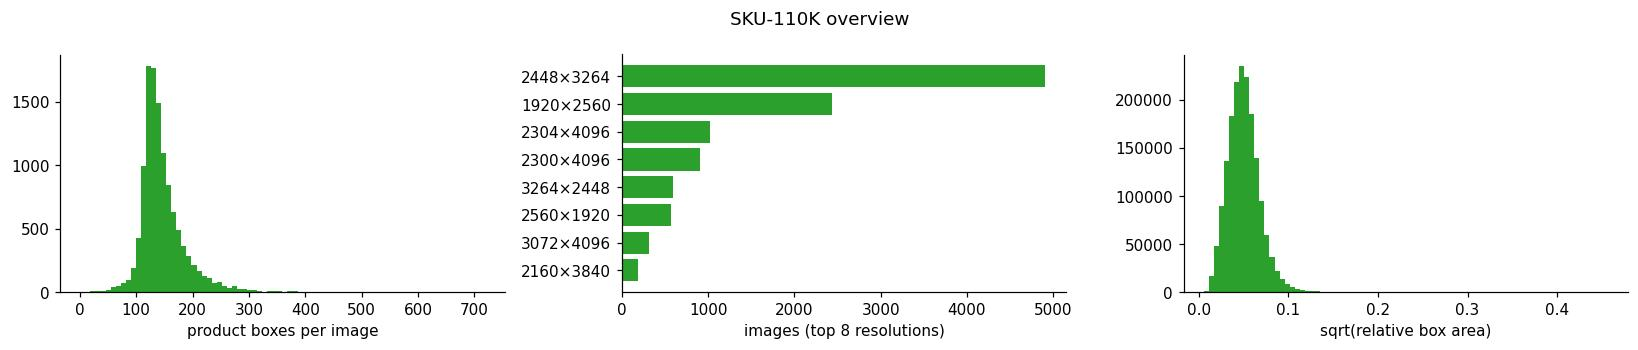

In [21]:
all_rel = np.concatenate(list(sku_boxes.values()))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].hist(sku["n_boxes"], bins=80, color="tab:green")
axes[0].set_xlabel("product boxes per image")
res = (sku["width"].astype(str) + "×" + sku["height"].astype(str)).value_counts().head(8)
axes[1].barh(res.index[::-1], res.values[::-1], color="tab:green")
axes[1].set_xlabel("images (top 8 resolutions)")
axes[2].hist(np.sqrt(all_rel[:, 3] * all_rel[:, 4]), bins=80, color="tab:green")
axes[2].set_xlabel("sqrt(relative box area)")
fig.suptitle("SKU-110K overview")
plt.tight_layout()
plt.show()

coverage:   0%|          | 0/11739 [00:00<?, ?it/s]

coverage:   1%|▏         | 148/11739 [00:00<00:07, 1469.85it/s]

coverage:   3%|▎         | 295/11739 [00:00<00:07, 1466.98it/s]

coverage:   4%|▍         | 452/11739 [00:00<00:07, 1512.44it/s]

coverage:   5%|▌         | 610/11739 [00:00<00:07, 1538.63it/s]

coverage:   7%|▋         | 764/11739 [00:00<00:07, 1535.97it/s]

... (64 outputs left out)

coverage:  97%|█████████▋| 11350/11739 [00:07<00:00, 1561.59it/s]

coverage:  98%|█████████▊| 11508/11739 [00:07<00:00, 1564.76it/s]

coverage:  99%|█████████▉| 11666/11739 [00:07<00:00, 1568.23it/s]

coverage: 100%|██████████| 11739/11739 [00:07<00:00, 1604.28it/s]

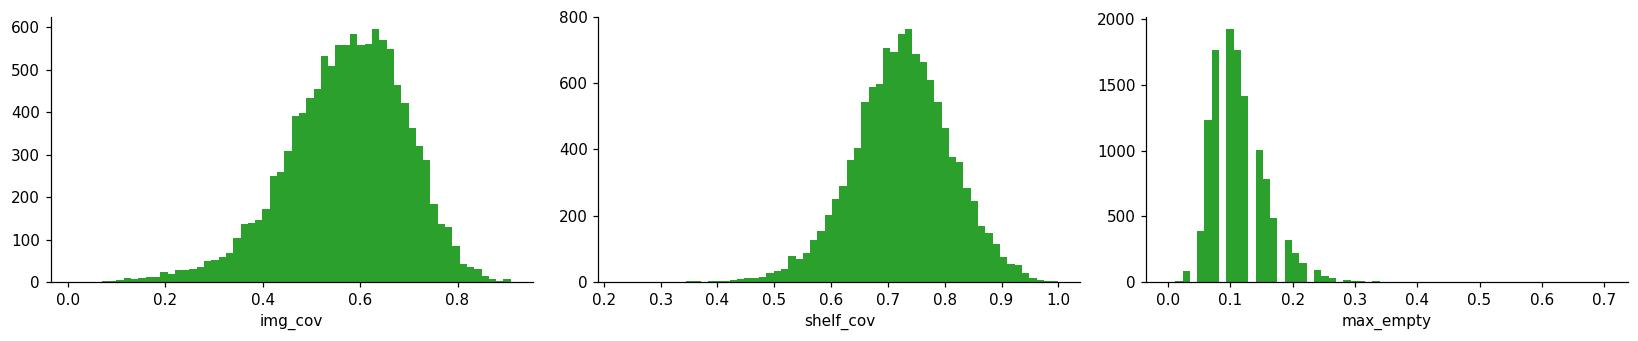

,img_cov,shelf_cov,max_empty
count,11739.000,11739.000,11739.000
mean,0.572,0.725,0.113
std,0.122,0.086,0.044
min,0.010,0.229,0.000
25%,0.496,0.670,0.078
50%,0.581,0.727,0.109
75%,0.658,0.782,0.141
max,0.909,1.000,0.703


In [22]:
GRID = 64


def stock_metrics(b):
    if len(b) == 0:
        return 0.0, 0.0, 1.0
    x1, x2 = b[:, 1] - b[:, 3] / 2, b[:, 1] + b[:, 3] / 2
    y1, y2 = b[:, 2] - b[:, 4] / 2, b[:, 2] + b[:, 4] / 2
    covered = np.zeros((GRID, GRID), bool)
    for a, c, e, f in zip(x1, x2, y1, y2):
        covered[int(max(e, 0) * GRID):int(np.ceil(min(f, 1) * GRID)),
                int(max(a, 0) * GRID):int(np.ceil(min(c, 1) * GRID))] = True
    ylo, yhi = np.quantile(y1, 0.02), np.quantile(y2, 0.98)
    xlo, xhi = np.quantile(x1, 0.02), np.quantile(x2, 0.98)
    empty = ~covered[int(max(ylo, 0) * GRID):int(np.ceil(min(yhi, 1) * GRID)),
                     int(max(xlo, 0) * GRID):int(np.ceil(min(xhi, 1) * GRID))]
    side = np.zeros(empty.shape, int)  # largest all-empty square ending at each cell
    for i in range(empty.shape[0]):
        for j in range(empty.shape[1]):
            if empty[i, j]:
                side[i, j] = 1 + min(side[i - 1, j] if i else 0, side[i, j - 1] if j else 0,
                                     side[i - 1, j - 1] if i and j else 0)
    return covered.mean(), 1 - empty.mean(), side.max() / GRID


m = [stock_metrics(sku_boxes[f]) for f in tqdm(sku["file"], desc="coverage")]
sku[["img_cov", "shelf_cov", "max_empty"]] = m

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, col in zip(axes, ["img_cov", "shelf_cov", "max_empty"]):
    ax.hist(sku[col], bins=60, color="tab:green")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()
sku[["img_cov", "shelf_cov", "max_empty"]].describe().round(3)

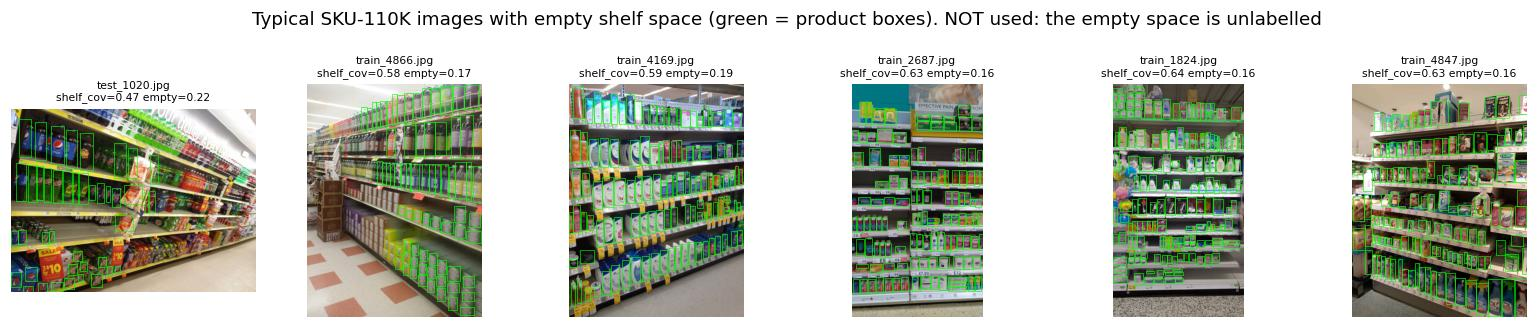

In [23]:
def decodes(path):
    try:
        Image.open(path).load()  # full decode, not just the header
        return True
    except OSError:
        return False


def sku_grid(rows, title, n_cols=6, with_boxes=True, fname=None):
    n_rows = int(np.ceil(len(rows) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.4 * n_cols, 3.0 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        im = Image.open(r["path"]).convert("RGB")
        im.thumbnail((480, 480))
        ax.imshow(im)
        if with_boxes:
            for _, cx, cy, w, h in sku_boxes[r["file"]]:
                ax.add_patch(patches.Rectangle(((cx - w / 2) * im.width, (cy - h / 2) * im.height),
                                               w * im.width, h * im.height, fill=False, lw=0.4, ec="lime"))
        ax.set_title(f"{r['file']}\nshelf_cov={r['shelf_cov']:.2f} empty={r['max_empty']:.2f}", fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()


# Typical SKU-110K images have visible empty space that is NOT labelled -> unusable as "no gap" examples
rejected = sku[(sku.shelf_cov < 0.65) & (sku.max_empty > 0.15)].sample(20, random_state=SEED)
sku_grid(rejected[[decodes(p) for p in rejected["path"]]].head(6),
         "Typical SKU-110K images with empty shelf space (green = product boxes). NOT used: the empty space is unlabelled",
         fname="sku_with_gaps_rejected.jpg")

80 candidates pass the coverage rule; 23 of them are truncated JPEGs and are dropped
-> 57 fully stocked shelves kept as background images


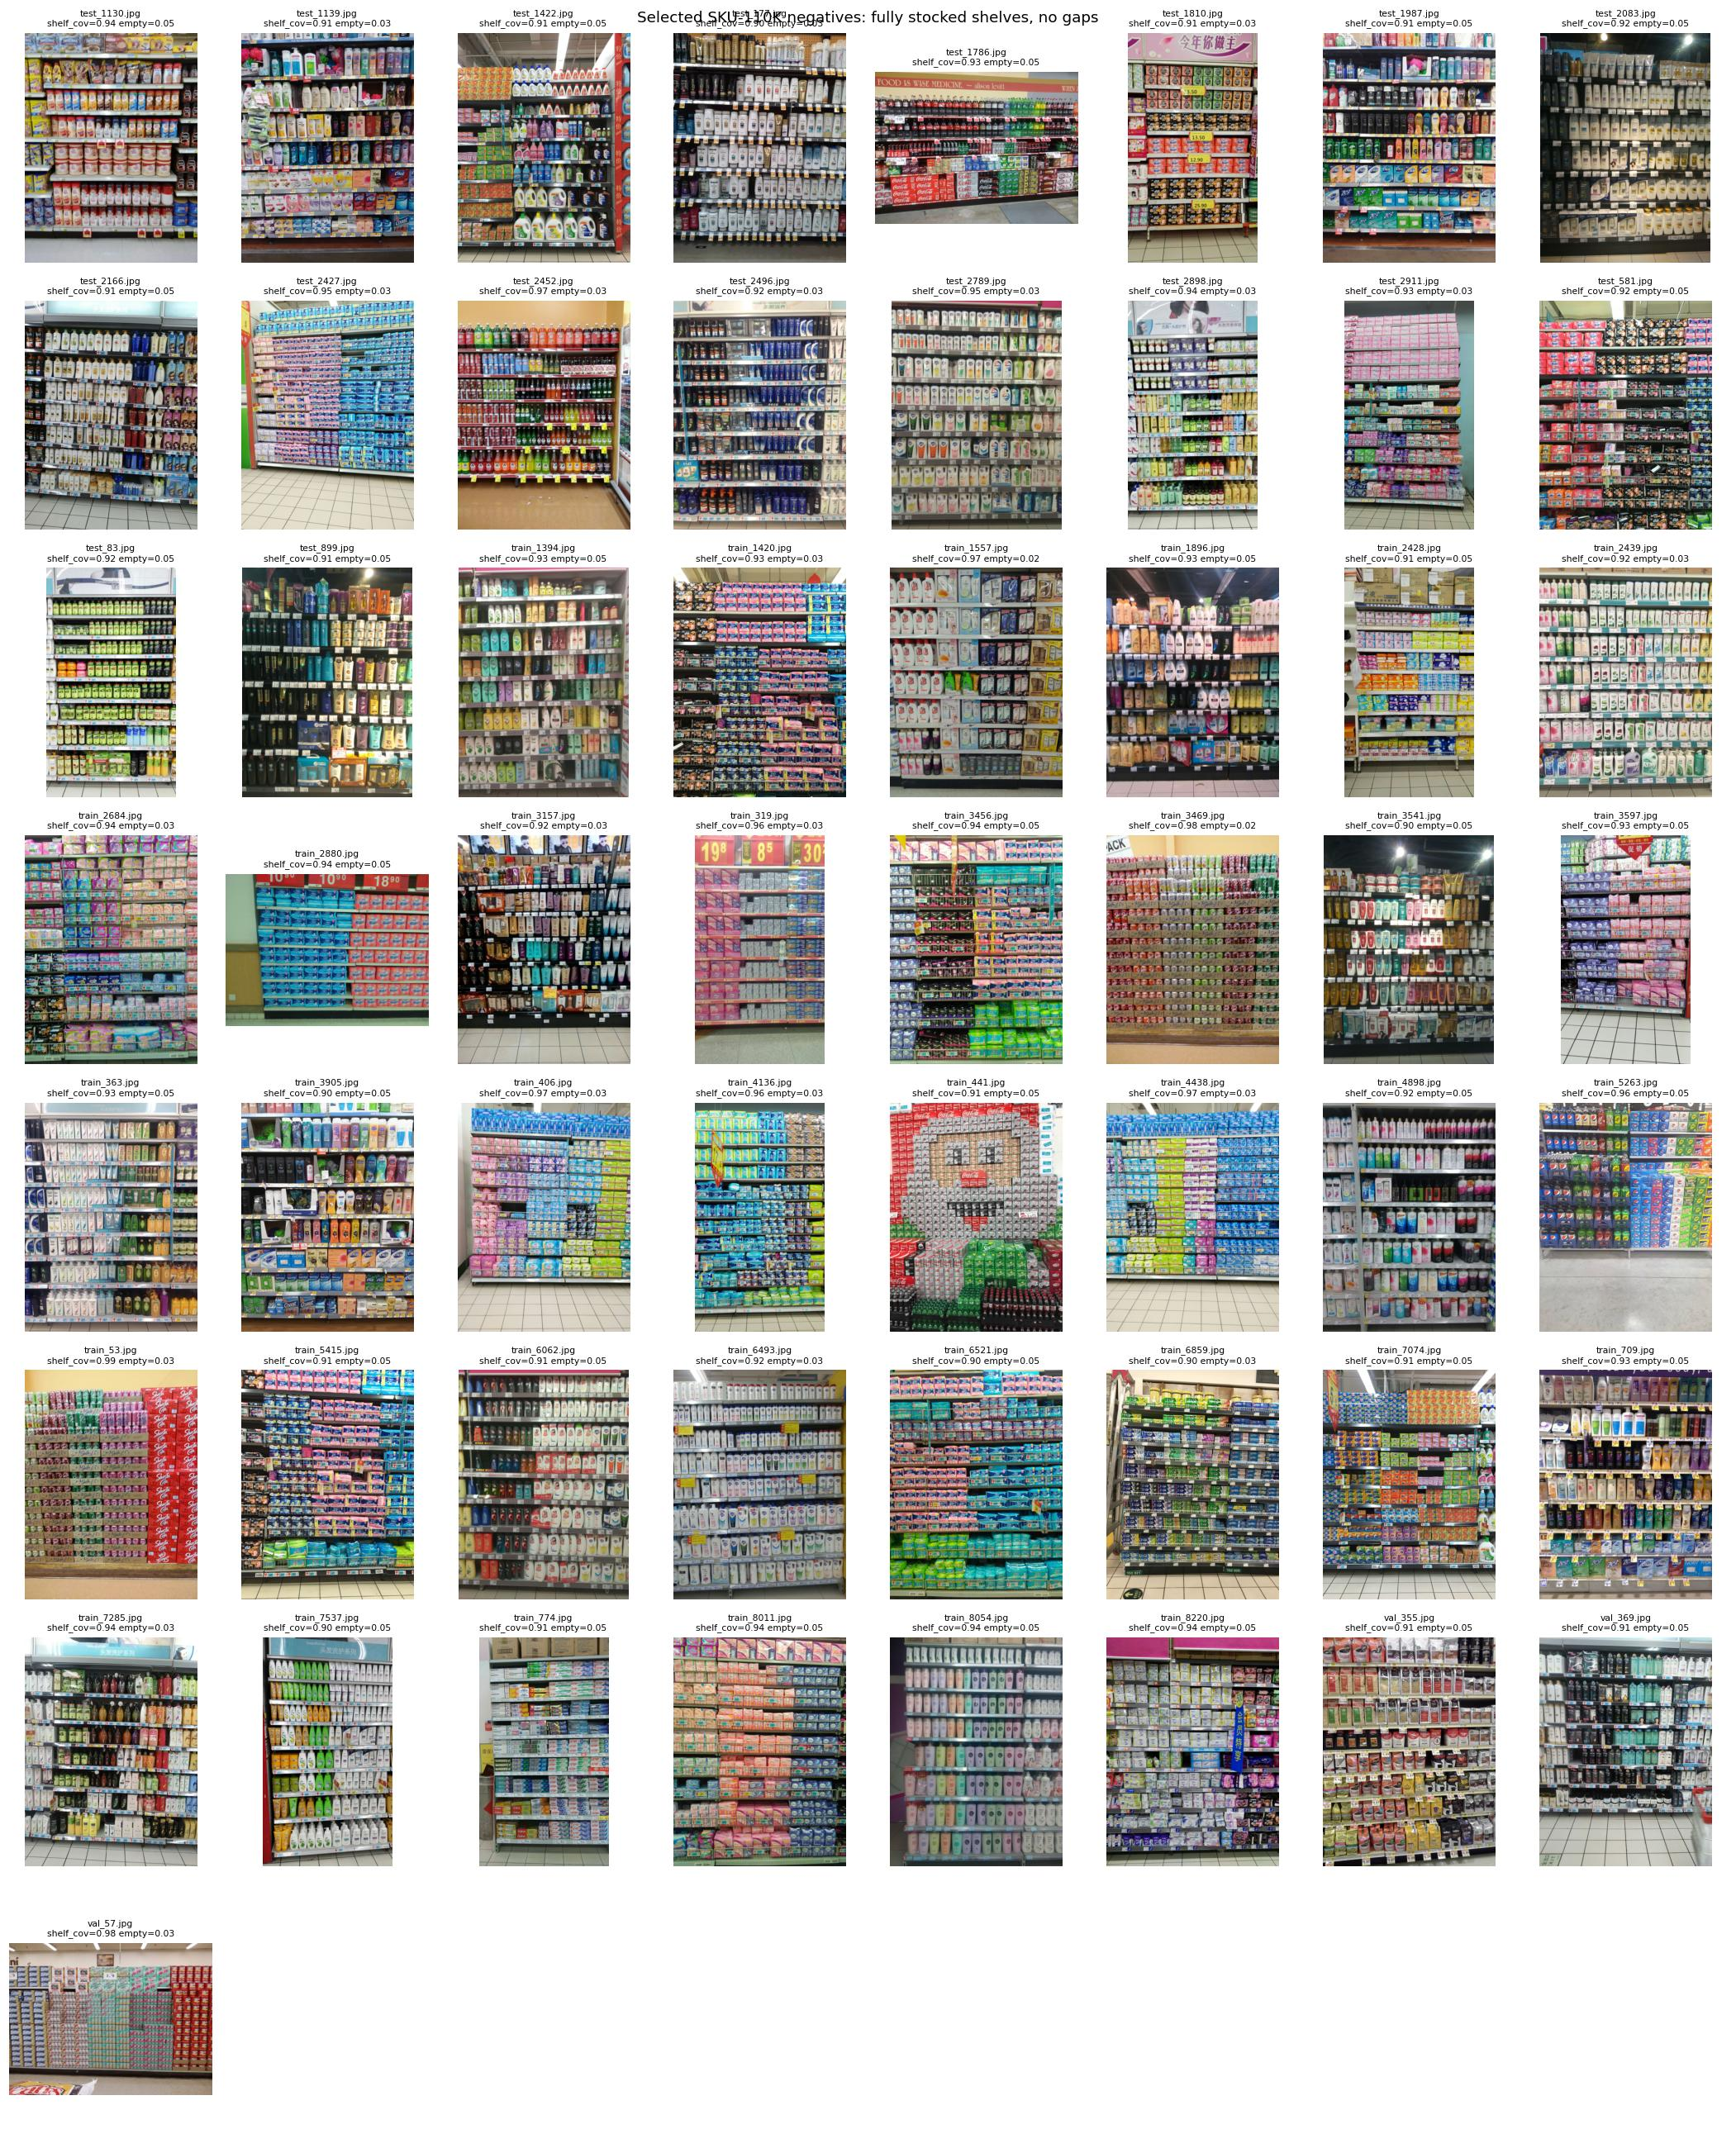

In [24]:
SHELF_COV_MIN, MAX_EMPTY_MAX, IMG_COV_MIN = 0.90, 0.05, 0.60

cand = sku[(sku.shelf_cov >= SHELF_COV_MIN) & (sku.max_empty <= MAX_EMPTY_MAX) & (sku.img_cov >= IMG_COV_MIN)].copy()



cand["decodes"] = [decodes(p) for p in cand["path"]]
print(f"{len(cand)} candidates pass the coverage rule; {int((~cand.decodes).sum())} of them are truncated JPEGs "
      f"and are dropped")
neg = cand[cand["decodes"]].sort_values("file").reset_index(drop=True)
print(f"-> {len(neg)} fully stocked shelves kept as background images")
sku_grid(neg, "Selected SKU-110K negatives: fully stocked shelves, no gaps", n_cols=8, with_boxes=False,
         fname="sku_negatives_selected.jpg")

**Observations**
- SKU-110K is very dense (~147 product boxes per image) and high-resolution, mostly 2448×3264 or 3264×2448 phone photos.
- Most of its images show some empty shelf space. Only a small share clear the strict "fully stocked" rule. The
  selected images above were checked by eye: shelves full from edge to edge, no visible gaps.
- Many of the strict candidates are **truncated JPEGs**, the same issue Ultralytics warns about for this dataset. They are
  dropped rather than repaired.
- The negatives are **resized so the longest side is 640 px** (aspect ratio kept), which matches the planned 640 px
  training size. They get **empty label files**, which tells YOLO "there are no gaps here". They are split 70/15/15 as
  well, so val/test can also measure false alarms on full shelves.

## 8. Write the YOLO datasets

| Dataset | Split | Contents | Used for |
|---|---|---|---|
| `data/processed/retail-gap/` | grouped 70/15/15 | cleaned labels, val/test copy-free, + SKU-110K negatives | **training & evaluation from now on** |
| `data/processed/retail-gap-original-split/` | Roboflow's original | cleaned labels only, every file kept | leakage comparison |

YOLO labels are `class cx cy w h`, normalised to 0–1. `data.yaml` has no `path:` key, so Ultralytics resolves the
splits relative to the yaml file itself. That makes the folder portable: zip it and upload it to Colab.

In [25]:
def yolo_lines(b):
    cx, cy = (b["x"] + b["w"] / 2) / W, (b["y"] + b["h"] / 2) / H
    return [f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n" for x, y, w, h in zip(cx, cy, b["w"] / W, b["h"] / H)]


def write_dataset(root, df, split_col, negatives=None):
    if root.exists():
        shutil.rmtree(root)
    by_uid = dict(tuple(boxes.groupby("uid")))
    for split in SPLITS:
        (root / "images" / split).mkdir(parents=True)
        (root / "labels" / split).mkdir(parents=True)
    for r in tqdm(df.itertuples(), total=len(df), desc=root.name):
        split = getattr(r, split_col)
        shutil.copy2(r.path, root / "images" / split / r.file)
        (root / "labels" / split / r.file).with_suffix(".txt").write_text("".join(yolo_lines(by_uid[r.uid])))
    for r in (negatives.itertuples() if negatives is not None else []):
        name = f"sku110k_{r.file}"
        im = ImageOps.exif_transpose(Image.open(r.path)).convert("RGB")
        im.thumbnail((640, 640))
        im.save(root / "images" / r.neg_split / name, quality=95)
        (root / "labels" / r.neg_split / name).with_suffix(".txt").write_text("")
    (root / "data.yaml").write_text(
        f"# {root.name}: built by notebooks/eda/1.0-qp-eda-and-cleaning.ipynb\n"
        "# no 'path' key: splits resolve relative to this file\n"
        "train: images/train\nval: images/val\ntest: images/test\n\nnames:\n  0: gap\n")


# negatives: 70/15/15 with the same seed
order = np.random.default_rng(SEED).permutation(len(neg))
cut1, cut2 = int(round(0.70 * len(neg))), int(round(0.85 * len(neg)))
neg["neg_split"] = ""
neg.loc[order[:cut1], "neg_split"] = "train"
neg.loc[order[cut1:cut2], "neg_split"] = "val"
neg.loc[order[cut2:], "neg_split"] = "test"

OUT_NEW = PROCESSED_DATA_DIR / "retail-gap"
OUT_ORIG = PROCESSED_DATA_DIR / "retail-gap-original-split"
write_dataset(OUT_NEW, imgs[imgs["keep"]], "split", negatives=neg)
write_dataset(OUT_ORIG, imgs, "orig_split")

INTERIM = INTERIM_DATA_DIR / "retail-gap"
INTERIM.mkdir(parents=True, exist_ok=True)
imgs[["uid", "file", "stem", "scene", "orig_split", "group", "copy_cluster", "split", "keep", "brightness"]].to_csv(
    INTERIM / "manifest.csv", index=False)
neg[["file", "split", "neg_split", "n_boxes", "img_cov", "shelf_cov", "max_empty"]].rename(
    columns={"split": "sku_split"}).to_csv(INTERIM / "sku110k_negatives.csv", index=False)

retail-gap:   0%|          | 0/3528 [00:00<?, ?it/s]

retail-gap:   4%|▎         | 128/3528 [00:00<00:02, 1274.32it/s]

retail-gap:   7%|▋         | 262/3528 [00:00<00:02, 1307.62it/s]

retail-gap:  11%|█▏        | 398/3528 [00:00<00:02, 1327.12it/s]

retail-gap:  15%|█▌        | 542/3528 [00:00<00:02, 1368.71it/s]

retail-gap:  19%|█▉        | 679/3528 [00:00<00:02, 1225.10it/s]

... (49 outputs left out)

retail-gap-original-split:  92%|█████████▏| 4214/4588 [00:02<00:00, 1437.84it/s]

retail-gap-original-split:  95%|█████████▍| 4358/4588 [00:03<00:00, 1416.35it/s]

retail-gap-original-split:  98%|█████████▊| 4500/4588 [00:03<00:00, 1410.02it/s]

retail-gap-original-split: 100%|██████████| 4588/4588 [00:03<00:00, 1411.06it/s]

In [26]:
def summarize(root):
    out = {}
    for split in SPLITS:
        labels = sorted((root / "labels" / split).glob("*.txt"))
        images = sorted((root / "images" / split).glob("*.jpg"))
        assert [p.stem for p in labels] == [p.stem for p in images], f"{root.name}/{split}: image/label mismatch"
        n_boxes = [len(p.read_text().splitlines()) for p in labels]
        out[split] = {"images": len(images), "gap boxes": sum(n_boxes),
                      "background (no gap)": sum(k == 0 for k in n_boxes)}
    return pd.DataFrame(out)


pd.concat({"retail-gap (grouped)": summarize(OUT_NEW), "original split": summarize(OUT_ORIG)})

train   val  test
retail-gap (grouped) images                3239   172   174
                     gap boxes            15665   764   808
                     background (no gap)     40     8     9
original split       images                3682   604   302
                     gap boxes            18114  3131  1770
                     background (no gap)      0     0     0

In [27]:
# Final leakage check on the new dataset: no group and no copy cluster in more than one split
final = imgs[imgs["keep"]]
assert final.groupby("group")["split"].nunique().max() == 1
assert final.groupby("copy_cluster")["split"].nunique().max() == 1
assert final.groupby("stem")["split"].nunique().max() == 1
print("OK: every stem, copy cluster and near-duplicate group lives in exactly one split")

OK: every stem, copy cluster and near-duplicate group lives in exactly one split


## 9. Summary

**Gap dataset (Roboflow)**
- 4,588 images, all stretched to 416×416. ~88% real store photos, ~12% one lab shelf.
- Only ~1,080 unique photos: train holds 3–6 copies of most photos.
- Labels: `UROP` was empty and `"0"` was a mislabelled batch of gaps. Both are cleaned up, leaving **one class, `gap`**.
- Box geometry is clean. Every image contains gaps, so there were no "no gap" examples.
- **The original split leaks heavily:** most val/test images have a copy (often a mirrored one) in train.

**What we built**
- Grouping rule: same Roboflow stem **or** flip-aware pHash ≤ 12 (store) / ≤ 4 (lab). Grouped 70/15/15 split of
  unique photos, stratified by scene. Val/test keep one image per photo.
- The lab shelf (~12%) is one scene, so some lab overlap between splits remains by nature. **Report mAP on the store
  images of the test set as the headline number**, next to the overall mAP.
- SKU-110K: only **fully stocked** shelves (strict coverage rule, checked by eye, truncated files removed), added as
  background images with empty labels across all three splits.
- `data/processed/retail-gap/`: use this for training and evaluation.
- `data/processed/retail-gap-original-split/`: same labels on the original split, for the leakage comparison.
- `data/interim/retail-gap/manifest.csv`: per-image stem, scene, group, original split, new split
  (`keep=False` = copy dropped from val/test). Use the `scene` column to compute the store-only mAP.

**Next steps**
1. Baseline: `yolo detect train data=data/processed/retail-gap/data.yaml model=yolo11n.pt epochs=10 imgsz=640`.
2. Train the same model on `retail-gap-original-split` and compare mAP, to quantify the leakage.
3. If Tahir's Roboflow re-export (640 px, original aspect, no augmentation) works out, rerun this notebook on it.
   Only `RF_DIR` and the 416 px constants need to change.
4. Add 50–100 of our own photos of fully stocked shelves from local stores, so there are negatives from our domain as well.